# Задачи 2.10 и 2.10*: Кривые на сфере Римана

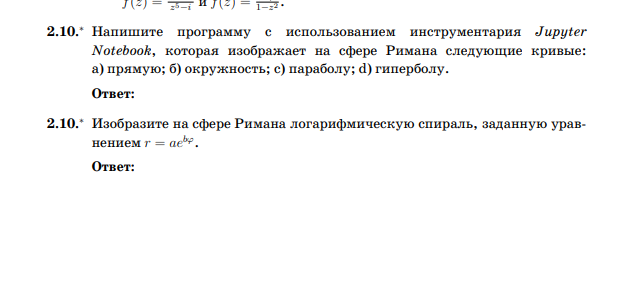

##  Математическая база

### Сфера Римана

Сфера Римана $\hat{\mathbb{C}} = \mathbb{C} \cup \{\infty\}$ — расширенная комплексная плоскость, реализуемая как единичная сфера:

$$S^2 = \{(X, Y, Z) \in \mathbb{R}^3 : X^2 + Y^2 + Z^2 = 1\}$$

### Стереографическая проекция

**Из плоскости на сферу** (для $z = x + iy$):

$$X = \frac{2x}{|z|^2 + 1}, \quad Y = \frac{2y}{|z|^2 + 1}, \quad Z = \frac{|z|^2 - 1}{|z|^2 + 1}$$

**Из сферы на плоскость:**

$$x = \frac{X}{1 - Z}, \quad y = \frac{Y}{1 - Z}$$

### Свойства

| Свойство | Описание |
|:---:|:---|
| Конформность | Сохраняет углы |
| Окружности ↔ окружности | Окружности переходят в окружности |
| Прямые → окружности через N | Прямая → окружность через северный полюс |
| $\infty \leftrightarrow N$ | Бесконечность соответствует северному полюсу |

---

##  Решение

### Задача 2.10: Кривые на сфере Римана

**a) Прямая** $y = mx + b$:

Параметризация: $z(t) = t + i(mt + b)$.

На сфере: окружность через $N = (0,0,1)$.

**b) Окружность** $|z - z_0| = R$:

Параметризация: $z(t) = z_0 + Re^{it}$.

На сфере: окружность.

**c) Парабола** $y = x^2$:

Параметризация: $z(t) = t + it^2$.

На сфере: кривая, стремящаяся к $N$.

**d) Гипербола** $xy = 1$:

Параметризация: $z(t) = t + i/t$.

На сфере: две ветви, стремящиеся к $N$.

### Задача 2.10*: Логарифмическая спираль

$r = ae^{b\varphi}$, параметризация: $z(\varphi) = ae^{(b+i)\varphi}$.

- $\varphi \to -\infty$: $z \to 0$ (южный полюс)
- $\varphi \to +\infty$: $|z| \to \infty$ (северный полюс)


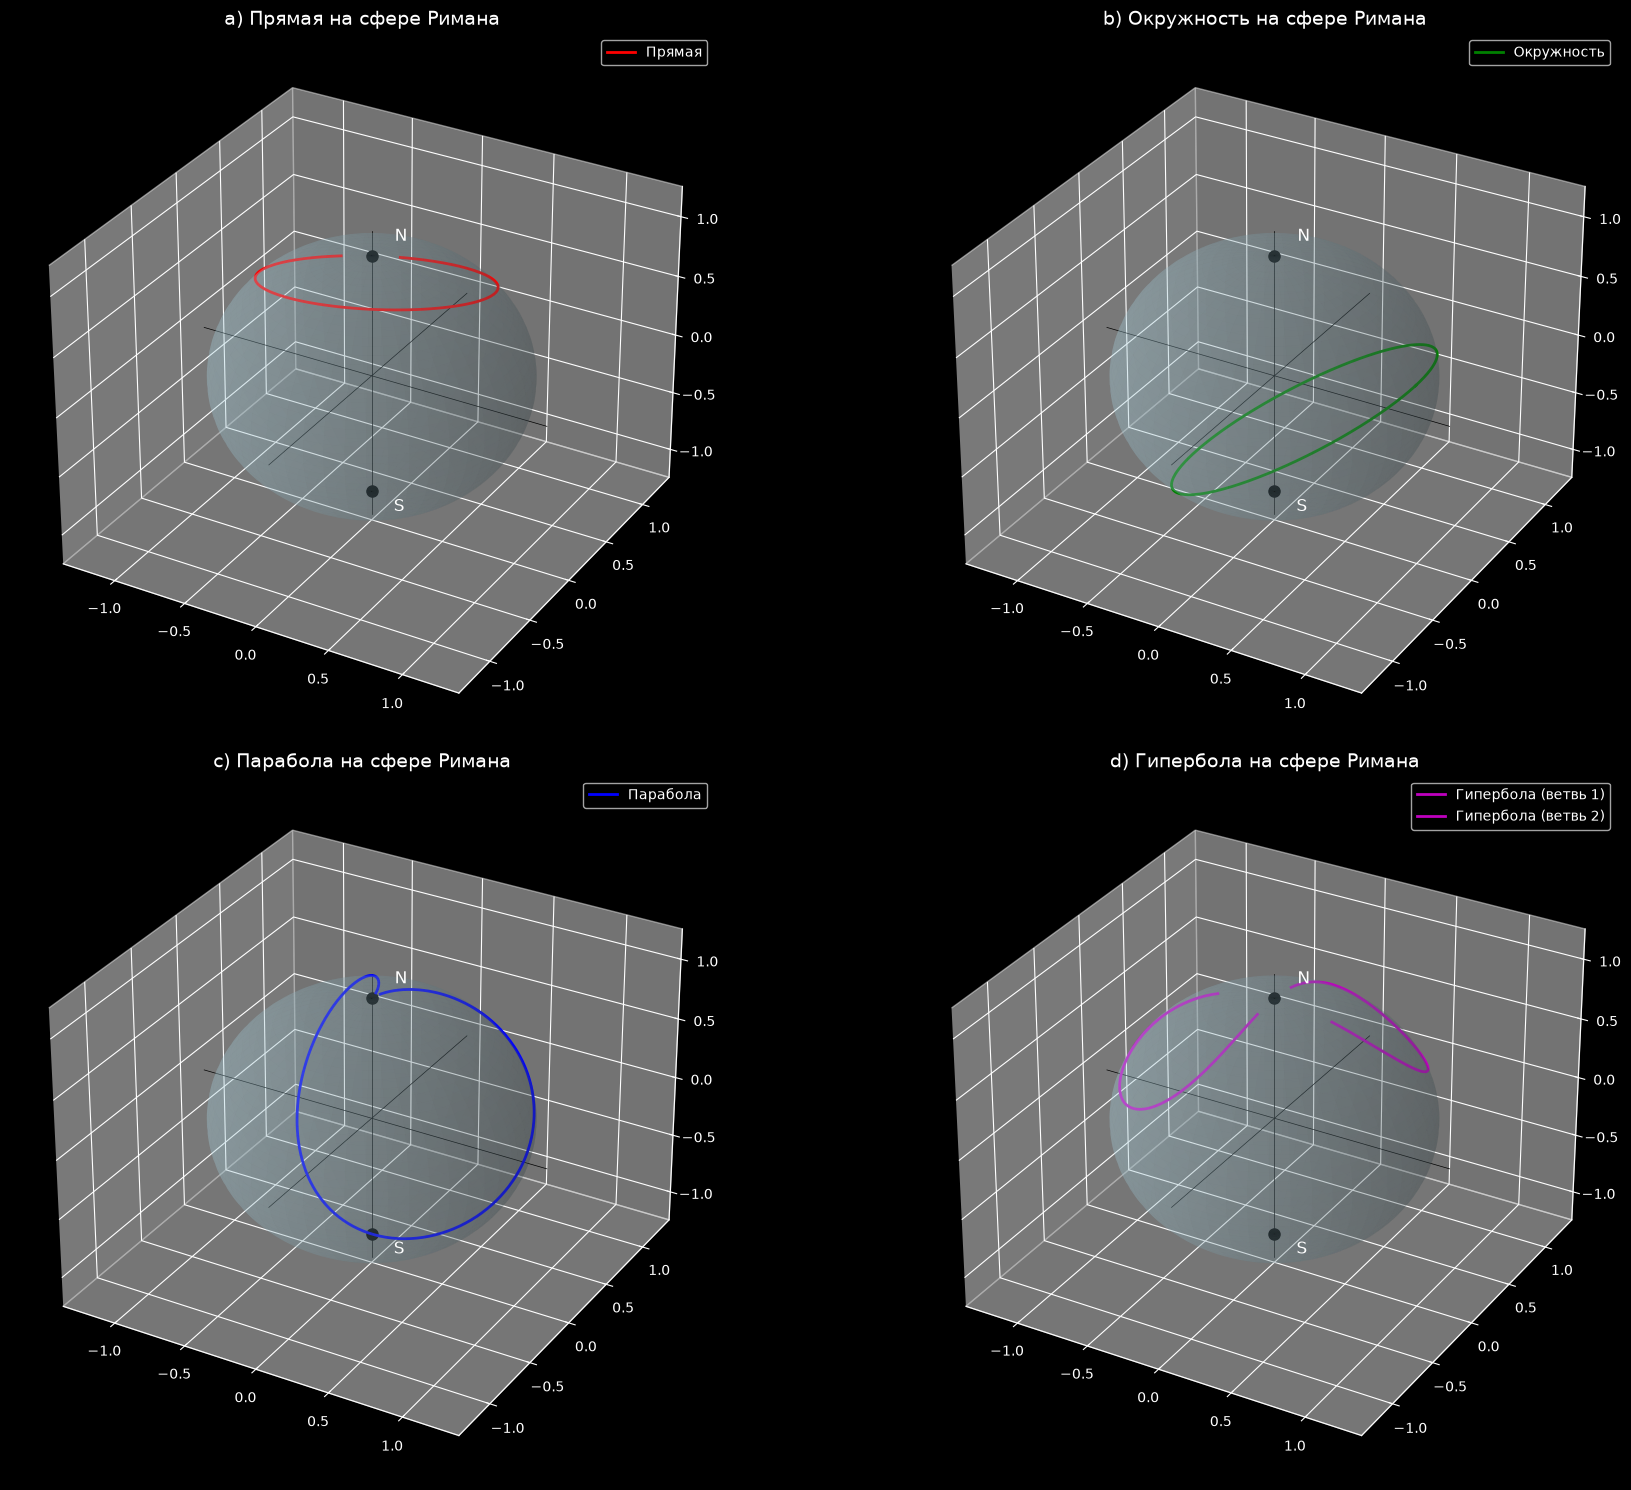

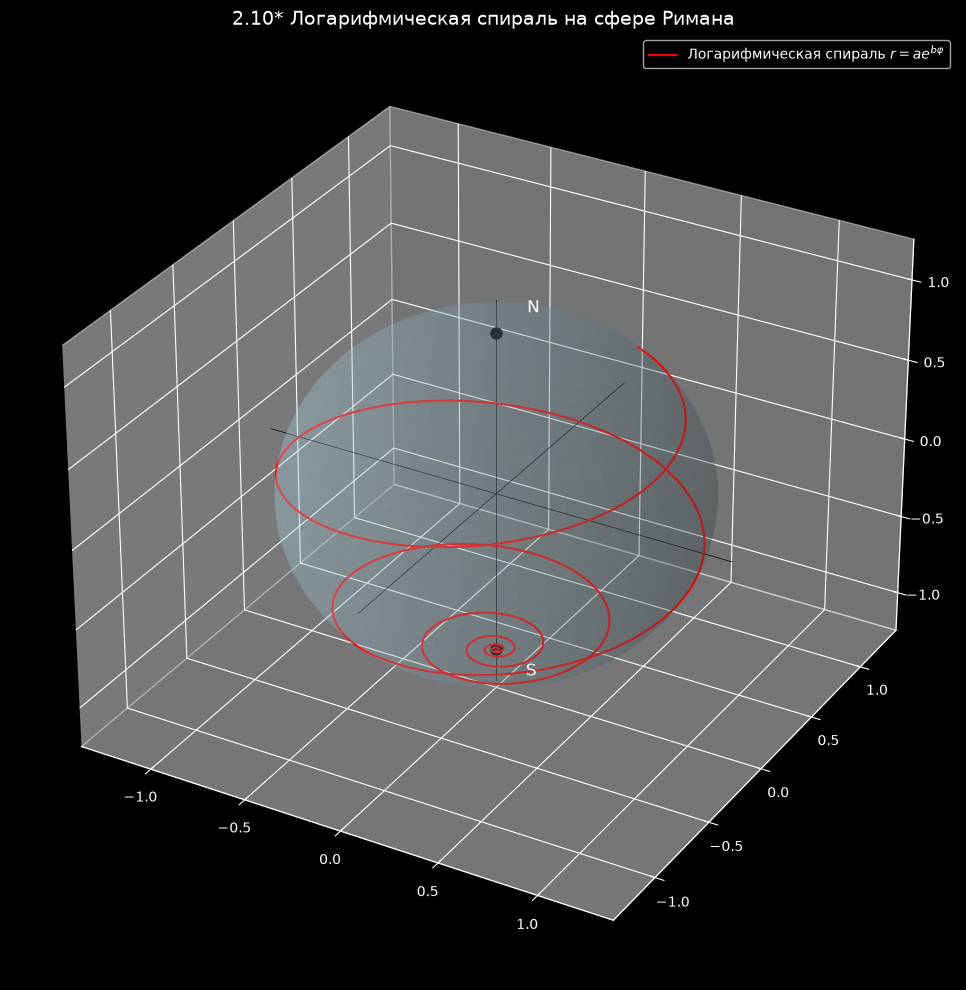

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D


def stereographic_projection(z):
    """Проецирует комплексное число z на сферу Римана."""
    x = np.real(z)
    y = np.imag(z)
    abs_z_sq = x**2 + y**2

    X = 2 * x / (abs_z_sq + 1)
    Y = 2 * y / (abs_z_sq + 1)
    Z = (abs_z_sq - 1) / (abs_z_sq + 1)

    return X, Y, Z


def create_sphere(ax):
    """Рисует единичную сферу."""
    u = np.linspace(0, 2 * np.pi, 100)
    v = np.linspace(0, np.pi, 100)
    X = np.outer(np.cos(u), np.sin(v))
    Y = np.outer(np.sin(u), np.sin(v))
    Z = np.outer(np.ones(np.size(u)), np.cos(v))

    ax.plot_surface(X, Y, Z, alpha=0.2, color='lightblue', edgecolor='none')

    # Оси
    ax.plot([-1.2, 1.2], [0, 0], [0, 0], 'k-', linewidth=0.5)
    ax.plot([0, 0], [-1.2, 1.2], [0, 0], 'k-', linewidth=0.5)
    ax.plot([0, 0], [0, 0], [-1.2, 1.2], 'k-', linewidth=0.5)

    # Северный и южный полюса
    ax.plot([0], [0], [1], 'ko', markersize=8)
    ax.plot([0], [0], [-1], 'ko', markersize=8)
    ax.text(0.1, 0.1, 1.1, 'N', fontsize=12)
    ax.text(0.1, 0.1, -1.2, 'S', fontsize=12)


t_line = np.linspace(-10, 10, 500)
z_line = t_line + 1j * (0.5 * t_line + 1)
X_line, Y_line, Z_line = stereographic_projection(z_line)


t_circle = np.linspace(0, 2 * np.pi, 500)
z_circle = 0.5 + 0.8 * np.exp(1j * t_circle)
X_circle, Y_circle, Z_circle = stereographic_projection(z_circle)


t_parabola = np.linspace(-5, 5, 500)
z_parabola = t_parabola + 1j * t_parabola**2
X_parabola, Y_parabola, Z_parabola = stereographic_projection(z_parabola)


t_hyperbola1 = np.linspace(0.1, 5, 250)
t_hyperbola2 = np.linspace(-5, -0.1, 250)
z_hyperbola1 = t_hyperbola1 + 1j / t_hyperbola1
z_hyperbola2 = t_hyperbola2 + 1j / t_hyperbola2
X_hyp1, Y_hyp1, Z_hyp1 = stereographic_projection(z_hyperbola1)
X_hyp2, Y_hyp2, Z_hyp2 = stereographic_projection(z_hyperbola2)


fig = plt.figure(figsize=(20, 15))

# a) Прямая
ax1 = fig.add_subplot(221, projection='3d')
create_sphere(ax1)
ax1.plot(X_line, Y_line, Z_line, 'r-', linewidth=2, label='Прямая')
ax1.set_title('a) Прямая на сфере Римана', fontsize=14)
ax1.legend()

# b) Окружность
ax2 = fig.add_subplot(222, projection='3d')
create_sphere(ax2)
ax2.plot(X_circle, Y_circle, Z_circle, 'g-', linewidth=2, label='Окружность')
ax2.set_title('b) Окружность на сфере Римана', fontsize=14)
ax2.legend()

# c) Парабола
ax3 = fig.add_subplot(223, projection='3d')
create_sphere(ax3)
ax3.plot(X_parabola, Y_parabola, Z_parabola, 'b-', linewidth=2, label='Парабола')
ax3.set_title('c) Парабола на сфере Римана', fontsize=14)
ax3.legend()

# d) Гипербола
ax4 = fig.add_subplot(224, projection='3d')
create_sphere(ax4)
ax4.plot(X_hyp1, Y_hyp1, Z_hyp1, 'm-', linewidth=2, label='Гипербола (ветвь 1)')
ax4.plot(X_hyp2, Y_hyp2, Z_hyp2, 'm-', linewidth=2, label='Гипербола (ветвь 2)')
ax4.set_title('d) Гипербола на сфере Римана', fontsize=14)
ax4.legend()

plt.tight_layout()
plt.savefig('task_2_10.png', dpi=150)
plt.show()


a = 0.1
b = 0.15
phi = np.linspace(-20, 20, 2000)
z_spiral = a * np.exp(b * phi) * np.exp(1j * phi)
X_spiral, Y_spiral, Z_spiral = stereographic_projection(z_spiral)

fig2 = plt.figure(figsize=(10, 10))
ax_spiral = fig2.add_subplot(111, projection='3d')
create_sphere(ax_spiral)
ax_spiral.plot(X_spiral, Y_spiral, Z_spiral, 'r-', linewidth=1.5,
               label=r'Логарифмическая спираль $r=ae^{b\varphi}$')
ax_spiral.set_title('2.10* Логарифмическая спираль на сфере Римана', fontsize=14)
ax_spiral.legend()
plt.tight_layout()
plt.savefig('task_2_10_star.png', dpi=150)
plt.show()